In [21]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [22]:
f = lambda x, y: x**2 + y**2

## Quasi Monte-Carlo
Anstatt hier die stützstellen komplett zufällig zu wählen, verwenden wir bei Quasi Monte-Carlo eine _Low Discrepancy Sequence_, die uns gleichmässig verteilte, zufällig wirkende Zahlen ausgibt. Hier seht Ihr den visuellen vergleich derer Verteilungen: 

Text(0.5, 1.0, 'Sobol Sequence')

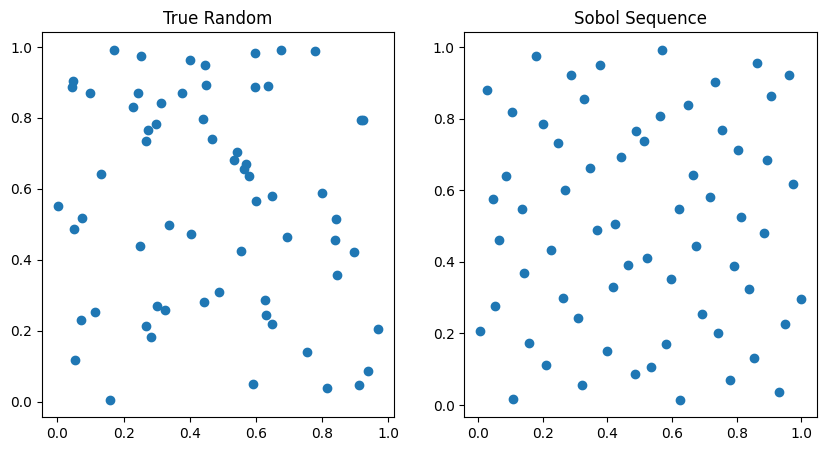

In [23]:
m = 6
n = 2**m

x0, y0 = np.random.rand(n), np.random.rand(n)

sobol = scipy.stats.qmc.Sobol(2)
x1, y1 = sobol.random_base2(m=m).T

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].scatter(x0, y0)
ax[0].set_title("True Random")
ax[1].scatter(x1, y1)
ax[1].set_title("Sobol Sequence")

Die Berechnung der Quadratur hier ist genau gleich für beide Methoden: 
$$w_i=\frac{1}{N}A$$
wobei A die Fläche (hier $1$) ist, und 
$$Q_N(f;A)=\sum_{i=1}^Nf(x_i,y_i)w_i$$
Wir berechnen einen Referenzwert mit Scipy's dblquad-Methode, die in _2D_ um einiges exakter ist als unsere Monte-Carlo-Methoden:

In [24]:
Q0 = np.sum(f(x0, y0)) / n
Q1 = np.sum(f(x1, y1)) / n
I = scipy.integrate.dblquad(f, 0, 1, 0, 1)[0]

print(f"Scipy Double Quad:\t{I}\nNormal Monte-Carlo:\t{Q0}\nQuasi Monte-Carlo:\t{Q1}")

Scipy Double Quad:	0.6666666666666669
Normal Monte-Carlo:	0.6950473477256551
Quasi Monte-Carlo:	0.6665762101042485


Hier sehen wir noch eine Darstellung der Messstellen auf der Funktion $f$:

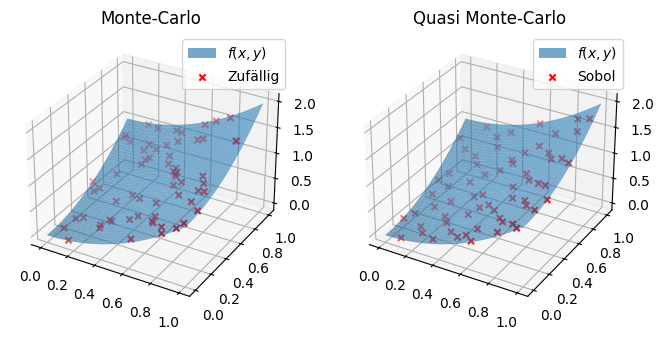

In [25]:
N = 500
a, b = 0, 1
X_,Y_= np.linspace(a, b, N), np.linspace(a, b, N)
X, Y = np.meshgrid(X_, Y_)
Z = f(X, Y)

fig, ax = plt.subplots(1, 2, figsize=(8, 8), subplot_kw={
    "projection": "3d"
})
ax[0].set_title("Monte-Carlo")
ax[0].plot_surface(X, Y, Z, alpha=0.6, edgecolor="none", label=r"$f(x, y)$")
ax[0].scatter(x0, y0, f(x0, y0), label="Zufällig", color="red", marker="x")
ax[0].legend()
ax[1].set_title("Quasi Monte-Carlo")
ax[1].plot_surface(X, Y, Z, alpha=0.6, edgecolor="none", label=r"$f(x, y)$")
ax[1].scatter(x1, y1, f(x1, y1), label="Sobol", color="red", marker="x")
ax[1].legend()
